# Лабораторна робота № 11
## Згорткова нейронна мережа для розпізнавання дорожніх знаків

**Дисципліна:** Машинне навчання
**Прізвище, ім’я:** Харченко Артьом
**Група:** ФІТ 3-10
**Дата:** 20.11.2026

**Мета:** побудувати згорткову нейронну мережу (CNN), яка розпізнає дорожні знаки з набору даних GTSRB (German Traffic Sign Recognition Benchmark).

**Порядок виконання:** 1) завантажити дані, 2) вивести зображення, 3) підготувати дані, 4) підібрати архітектуру моделі, 5) вивести криві навчання, 6) оцінити модель, 7) показати візуалізацію класифікації, 8) зробити висновки.

## 1. Завантаження даних

Набір даних **GTSRB** з Kaggle: фото німецьких дорожніх знаків, **43 класи**. У навчальній частині близько 39 тисяч зображень, у тестовій близько 12.6 тисяч. Розміри картинок різні, тому всі зменшуємо до **32 × 32** пікселі.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

# щоб результати були більш-менш однакові між запусками
keras.utils.set_random_seed(42)

# завантажуємо датасет з Kaggle
data_dir = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Папка з даними:", data_dir)
print("Вміст:", os.listdir(data_dir))

train_df = pd.read_csv(os.path.join(data_dir, "Train.csv"))
test_df = pd.read_csv(os.path.join(data_dir, "Test.csv"))
print("Train.csv:", train_df.shape, "| Test.csv:", test_df.shape)
train_df.head()

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Папка з даними: /kaggle/input/gtsrb-german-traffic-sign
Вміст: ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']
Train.csv: (39209, 8) | Test.csv: (12630, 8)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [2]:
# назви 43 класів знаків
class_names = [
    "Speed limit 20", "Speed limit 30", "Speed limit 50", "Speed limit 60", "Speed limit 70",
    "Speed limit 80", "End of speed limit 80", "Speed limit 100", "Speed limit 120", "No passing",
    "No passing for trucks", "Right-of-way at intersection", "Priority road", "Yield", "Stop",
    "No vehicles", "Trucks prohibited", "No entry", "General caution", "Curve to the left",
    "Curve to the right", "Double curve", "Bumpy road", "Slippery road", "Road narrows on the right",
    "Road work", "Traffic signals", "Pedestrians", "Children crossing", "Bicycles crossing",
    "Ice or snow", "Wild animals crossing", "End of all limits", "Turn right ahead", "Turn left ahead",
    "Ahead only", "Go straight or right", "Go straight or left", "Keep right", "Keep left",
    "Roundabout", "End of no passing", "End of no passing for trucks",
]
num_classes = len(class_names)
print("Кількість класів:", num_classes)


def load_images(paths, size=32):
    # відкриваємо кожну картинку і зменшуємо до size x size
    images = []
    for p in paths:
        img = Image.open(os.path.join(data_dir, p)).convert("RGB").resize((size, size))
        images.append(np.array(img))
    return np.array(images, dtype="uint8")


x_all = load_images(train_df["Path"])
y_all = train_df["ClassId"].values
x_test = load_images(test_df["Path"])
y_test = test_df["ClassId"].values

print("x_all:", x_all.shape, "| y_all:", y_all.shape)
print("x_test:", x_test.shape, "| y_test:", y_test.shape)

Кількість класів: 43
x_all: (39209, 32, 32, 3) | y_all: (39209,)
x_test: (12630, 32, 32, 3) | y_test: (12630,)


## 2. Зображення з набору даних

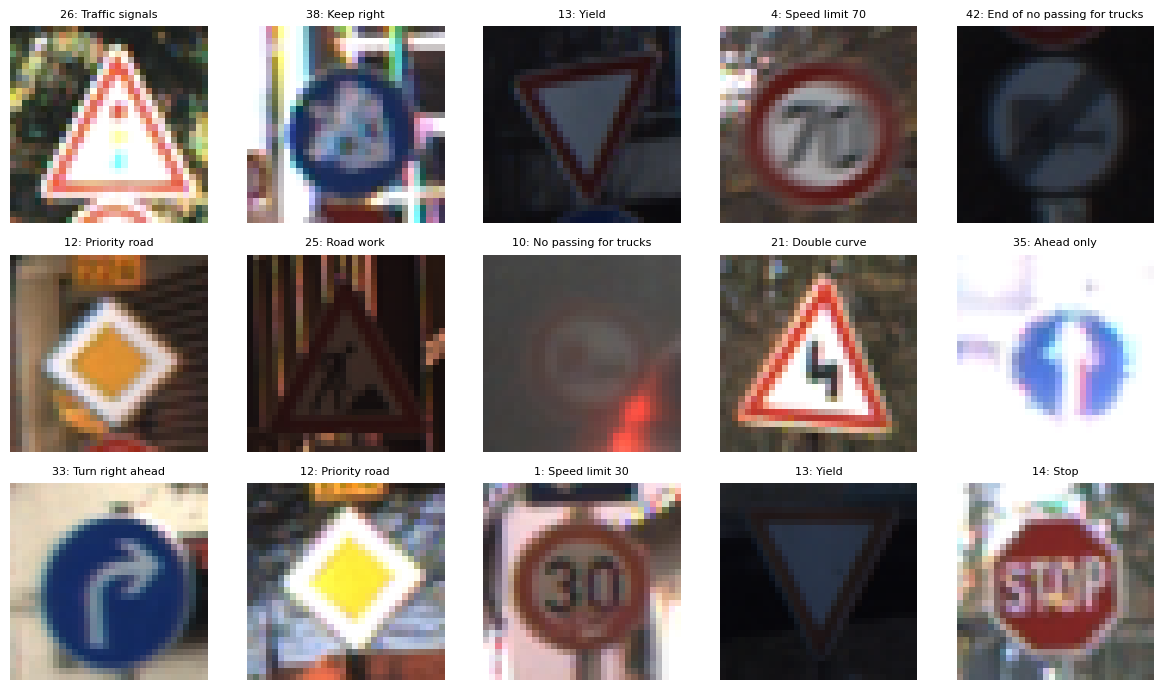

In [3]:
# 15 випадкових картинок з навчальної вибірки
rng = np.random.RandomState(1)
idx = rng.choice(len(x_all), 15, replace=False)

plt.figure(figsize=(12, 7))
for k, i in enumerate(idx):
    plt.subplot(3, 5, k + 1)
    plt.imshow(x_all[i])
    plt.title(str(y_all[i]) + ": " + class_names[y_all[i]], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

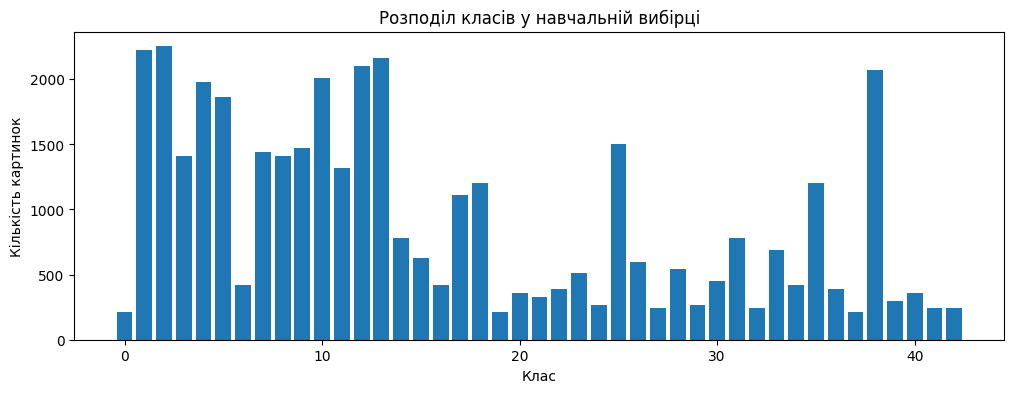

Найменше картинок: 210 (клас 0 )
Найбільше картинок: 2250 (клас 2 )


In [4]:
# скільки картинок у кожному класі
counts = np.bincount(y_all, minlength=num_classes)

plt.figure(figsize=(12, 4))
plt.bar(range(num_classes), counts)
plt.xlabel("Клас")
plt.ylabel("Кількість картинок")
plt.title("Розподіл класів у навчальній вибірці")
plt.show()

print("Найменше картинок:", counts.min(), "(клас", counts.argmin(), ")")
print("Найбільше картинок:", counts.max(), "(клас", counts.argmax(), ")")

**Короткі спостереження:** у навчальній вибірці 39209 картинок і 43 класи. Класи дуже нерівні: у класі 0 (обмеження швидкості 20) лише 210 картинок, а у класі 2 (обмеження 50) аж 2250. На фото видно, що якість різна: багато темних, розмитих і дуже малих картинок, тому розпізнати знак буває непросто.

## 3. Підготовка даних

Значення пікселів ділимо на 255, щоб вони були від 0 до 1. Навчальні дані ділимо на train (80%) і validation (20%), тестову вибірку залишаємо для фінальної оцінки.

In [5]:
x_all = x_all.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Діапазон значень:", x_all.min(), "-", x_all.max())

x_train, x_val, y_train, y_val = train_test_split(
    x_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)
print("Train:", x_train.shape, "| Val:", x_val.shape, "| Test:", x_test.shape)

Діапазон значень: 0.0 - 1.0
Train: (31367, 32, 32, 3) | Val: (7842, 32, 32, 3) | Test: (12630, 32, 32, 3)


## 4. Підбір архітектури моделі

Порівнюємо три варіанти згорткової мережі:
- **A**: 1 блок (два шари Conv, MaxPooling, Dropout),
- **B**: 2 блоки (кількість фільтрів 32 і 64),
- **C**: як B, але з BatchNorm після кожного шару Conv.

Після блоків іде Flatten, Dense(256) з Dropout 0.5 і вихід на 43 нейрони з softmax. Кожну модель вчимо до 10 епох із EarlyStopping, найкращу обираємо за точністю на validation.

In [6]:
def build_cnn(blocks, batchnorm=False):
    model = keras.Sequential()
    model.add(layers.Input(shape=(32, 32, 3)))
    filters = 32
    for _ in range(blocks):
        model.add(layers.Conv2D(filters, 3, padding="same", activation="relu"))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Conv2D(filters, 3, padding="same", activation="relu"))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D())
        model.add(layers.Dropout(0.25))
        filters *= 2
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation="relu"))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


variants = {
    "A: 1 блок": dict(blocks=1),
    "B: 2 блоки": dict(blocks=2),
    "C: 2 блоки + BatchNorm": dict(blocks=2, batchnorm=True),
}

trained = {}
histories = {}
rows = []
for name, params in variants.items():
    keras.utils.set_random_seed(42)
    m = build_cnn(**params)
    h = m.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=10, batch_size=128,
              callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
              verbose=2)
    trained[name] = m
    histories[name] = h
    rows.append({
        "Модель": name,
        "Параметрів": m.count_params(),
        "Епох": len(h.history["loss"]),
        "Train acc": max(h.history["accuracy"]),
        "Val acc": max(h.history["val_accuracy"]),
    })

arch_table = pd.DataFrame(rows).set_index("Модель")
display(arch_table.round(4))

Epoch 1/10
246/246 - 20s - 81ms/step - accuracy: 0.5920 - loss: 1.4901 - val_accuracy: 0.9280 - val_loss: 0.3037
Epoch 2/10
246/246 - 2s - 9ms/step - accuracy: 0.8937 - loss: 0.3584 - val_accuracy: 0.9751 - val_loss: 0.1233
Epoch 3/10
246/246 - 2s - 9ms/step - accuracy: 0.9416 - loss: 0.2002 - val_accuracy: 0.9770 - val_loss: 0.0873
Epoch 4/10
246/246 - 2s - 9ms/step - accuracy: 0.9572 - loss: 0.1390 - val_accuracy: 0.9881 - val_loss: 0.0572
Epoch 5/10
246/246 - 2s - 8ms/step - accuracy: 0.9694 - loss: 0.1017 - val_accuracy: 0.9870 - val_loss: 0.0536
Epoch 6/10
246/246 - 2s - 8ms/step - accuracy: 0.9751 - loss: 0.0837 - val_accuracy: 0.9890 - val_loss: 0.0463
Epoch 7/10
246/246 - 2s - 8ms/step - accuracy: 0.9778 - loss: 0.0720 - val_accuracy: 0.9908 - val_loss: 0.0388
Epoch 8/10
246/246 - 2s - 8ms/step - accuracy: 0.9799 - loss: 0.0641 - val_accuracy: 0.9895 - val_loss: 0.0471
Epoch 9/10
246/246 - 2s - 8ms/step - accuracy: 0.9834 - loss: 0.0543 - val_accuracy: 0.9927 - val_loss: 0.0357

,Параметрів,Епох,Train acc,Val acc
Модель,,,,
A: 1 блок,2118603,10,0.9838,0.9927
B: 2 блоки,1125451,10,0.9858,0.9964
C: 2 блоки + BatchNorm,1126219,10,0.9880,0.9973


In [7]:
# обираємо найкращу архітектуру за точністю на validation
best_name = arch_table["Val acc"].idxmax()
model = trained[best_name]
history = histories[best_name]
print("Найкраща архітектура:", best_name)
model.summary()

Найкраща архітектура: C: 2 блоки + BatchNorm


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,377,891 (12.89 MB)

 Trainable params: 1,125,835 (4.29 MB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 2,251,672 (8.59 MB)

**Результат порівняння архітектур:** усі три варіанти дали схожу точність на validation (близько 0.993-0.997). Найкращою за val accuracy стала архітектура **B** (2 блоки, 0.9966). Вона має менше параметрів (близько 1.1 млн), ніж A (близько 2.1 млн), бо після двох шарів MaxPooling у Dense потрапляє менше ознак. BatchNorm (варіант C) результат не покращив (0.9954), тому ускладнювати модель не стали. Те, що на графіках val accuracy вища за train accuracy, нормально: під час навчання працює Dropout, а на validation він вимкнений.

## 5. Криві навчання

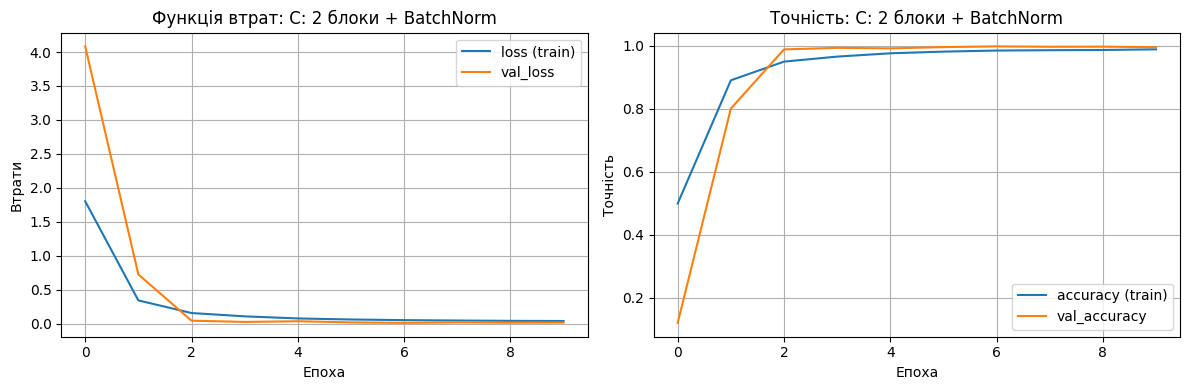

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="loss (train)")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Епоха")
plt.ylabel("Втрати")
plt.title("Функція втрат: " + best_name)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="accuracy (train)")
plt.plot(history.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Епоха")
plt.ylabel("Точність")
plt.title("Точність: " + best_name)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

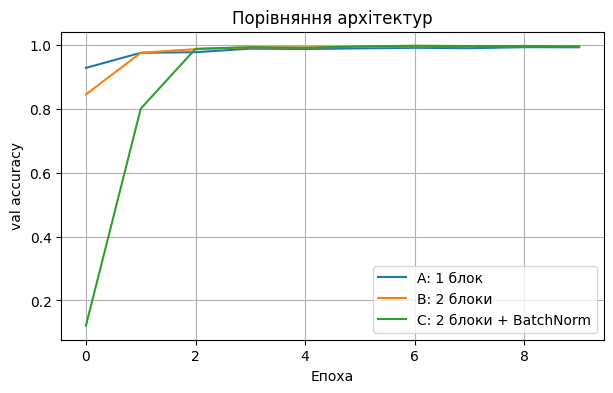

In [9]:
# для порівняння: val accuracy всіх трьох архітектур
plt.figure(figsize=(7, 4))
for name, h in histories.items():
    plt.plot(h.history["val_accuracy"], label=name)
plt.xlabel("Епоха")
plt.ylabel("val accuracy")
plt.title("Порівняння архітектур")
plt.legend()
plt.grid(True)
plt.show()

## 6. Оцінка моделі на тестовій вибірці

In [10]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_acc, 4))

# прогнозовані класи
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)

# точність по кожному класу, показуємо 5 найгірших
per_class = []
for c in range(num_classes):
    mask = y_test == c
    per_class.append((c, class_names[c], mask.sum(), np.mean(y_pred[mask] == c)))
worst = sorted(per_class, key=lambda t: t[3])[:5]

print()
print("5 класів із найменшою точністю:")
for c, name, n, acc in worst:
    print("  клас", c, name, "| картинок:", n, "| точність:", round(acc, 3))
print("Помилок усього:", int((y_pred != y_test).sum()), "з", len(y_test))

Test loss: 0.1054
Test accuracy: 0.9749

5 класів із найменшою точністю:
  клас 41 End of no passing | картинок: 60 | точність: 0.8
  клас 6 End of speed limit 80 | картинок: 150 | точність: 0.82
  клас 30 Ice or snow | картинок: 150 | точність: 0.82
  клас 21 Double curve | картинок: 90 | точність: 0.833
  клас 26 Traffic signals | картинок: 180 | точність: 0.872
Помилок усього: 317 з 12630


## 7. Візуалізація класифікації

Для кожної картинки показано справжній і прогнозований клас: зелений підпис, якщо модель вгадала, червоний, якщо помилилась.

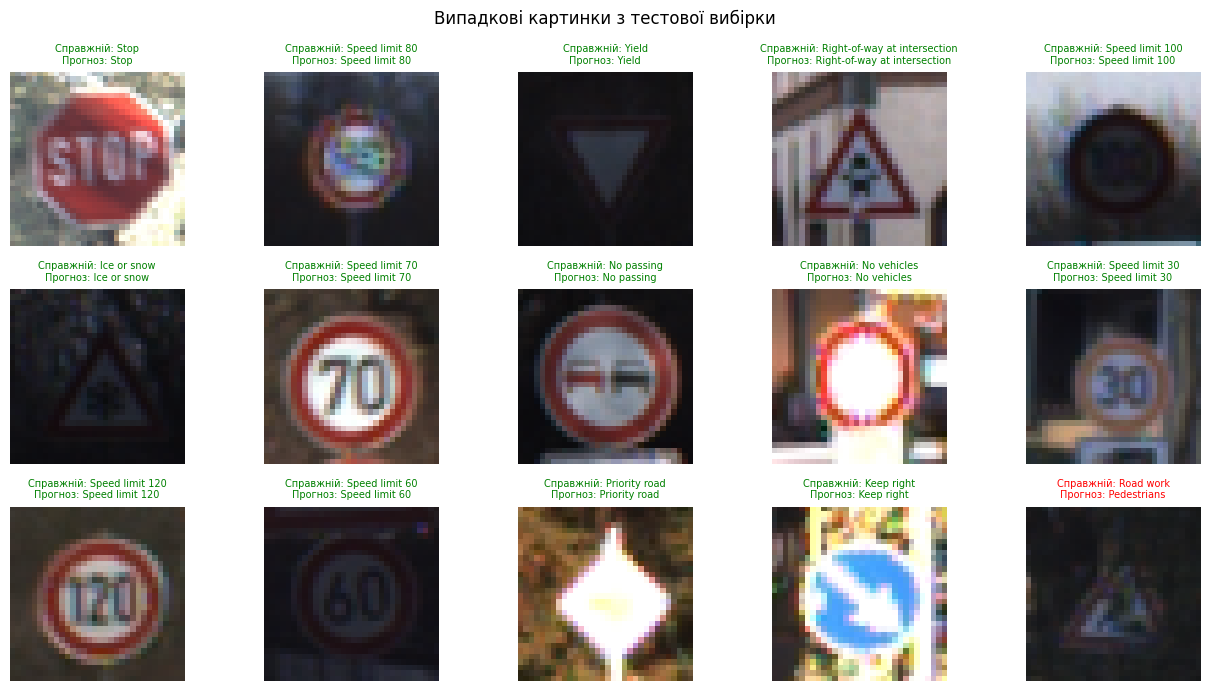

In [11]:
def show(indices, title):
    plt.figure(figsize=(13, 7))
    for k, i in enumerate(indices):
        plt.subplot(3, 5, k + 1)
        plt.imshow(x_test[i])
        color = "green" if y_pred[i] == y_test[i] else "red"
        plt.title("Справжній: " + class_names[y_test[i]] + "\nПрогноз: " + class_names[y_pred[i]],
                  color=color, fontsize=7)
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# 15 випадкових тестових картинок
rng = np.random.RandomState(7)
show(rng.choice(len(x_test), 15, replace=False), "Випадкові картинки з тестової вибірки")

Усього помилок: 317


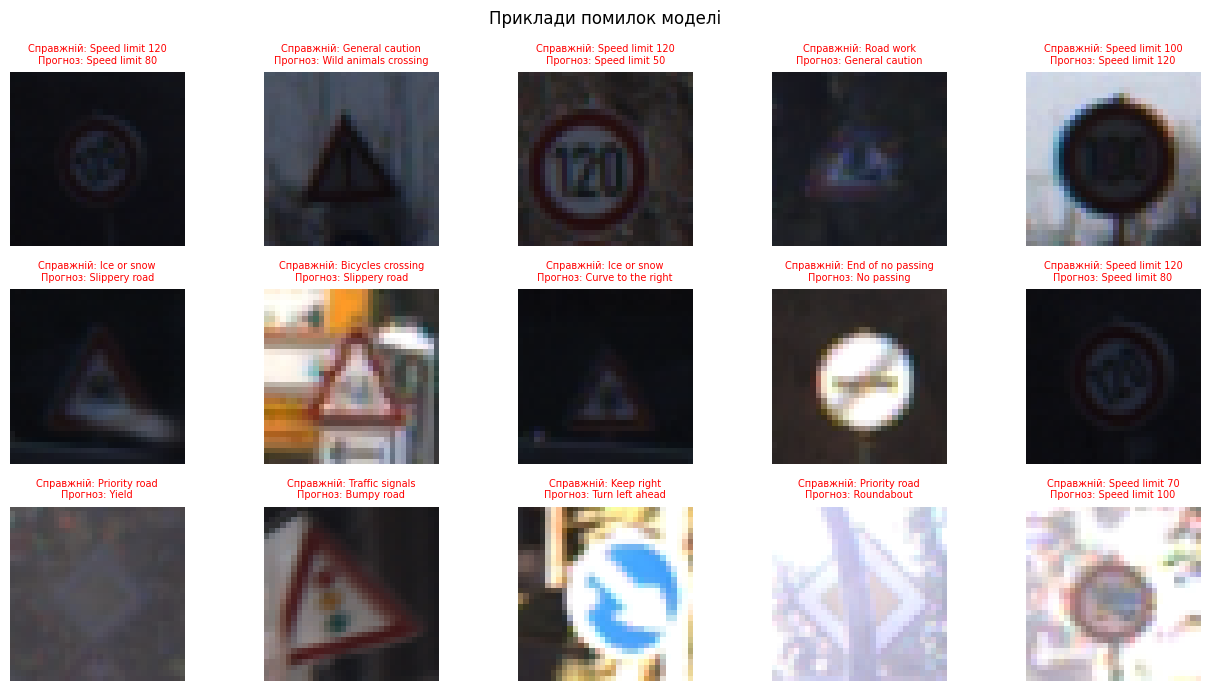

In [12]:
# картинки, на яких модель помилилась
wrong = np.where(y_pred != y_test)[0]
print("Усього помилок:", len(wrong))
show(wrong[:15], "Приклади помилок моделі")

## 8. Висновки

Ми побудували згорткову мережу для розпізнавання 43 класів дорожніх знаків із набору GTSRB: картинки зменшили до 32 × 32, поділили дані на train, validation і test. З трьох архітектур найкращою виявилась B (2 блоки з Conv, MaxPooling і Dropout), її точність на validation близько 0.997, і вона вдвічі менша за варіант A за кількістю параметрів. На тестовій вибірці отримали accuracy 0.974 (loss близько 0.12), тобто з 12630 знаків модель помилилась приблизно в 330. Точність на тесті трохи нижча, ніж на validation, бо в навчальних даних багато майже однакових кадрів одного й того ж знака, тому validation трохи оптимістична. Гірше за все розпізнаються Pedestrians (близько 50%), Double curve (близько 63%) і Traffic signals (близько 83%): це схожі трикутні знаки з дрібними деталями, до того ж у цих класів мало картинок. Криві навчання плавні, val_loss не росте, тобто сильного перенавчання немає, а щоб покращити результат, можна додати аугментацію (повороти, зміна яскравості) і більше фото рідкісних класів.